In [1]:
import PyPreprocess
import PolarDecomp
import importlib
import os, datetime, netCDF4
import numpy as np
import torch
import torch.nn.functional as F
import scipy
import matplotlib.pyplot as plt

In [220]:
from osgeo import gdal

In [2]:
importlib.reload(PyPreprocess)
cache_dir = 'SNAPNative_Greenland_s1'

if(True):
    dataset = PyPreprocess.Single_Dataset_SNAPbase(
        src_fn = "/mnt/c/Users/user/Desktop/slc_cache/251114rGreenland/ALPSRP060811420-L1.1.zip",
        cache_dir = cache_dir,
        read_nc = True,
        alos1_deskew = True
    ); dataset.cache()
else:
    dataset = PyPreprocess.Pair_Dataset_SNAPbase.load_cache(cache_dir)

'''slc_date = datetime.datetime.strptime(dataset.metadata['0dopp_t0'][0][:11], '%d-%b-%Y')
siconc_fn = [el for el in os.listdir('nextSim_cache') if 'siconc' in el and slc_date.strftime('_%Y-%m') in el][0]
siconc_ds = netCDF4.Dataset('nextSim_cache'+'/'+siconc_fn, 'r')

aux_lat, aux_lon = siconc_ds.variables['latitude'][:], siconc_ds.variables['longitude'][:] #1D arrays
siconc = torch.as_tensor(siconc_ds.variables['siconc'][0])
siconc[torch.isnan(siconc)] = 0

grid = torch.empty(1, dataset.lat.shape[0], dataset.lat.shape[1], 2, dtype=siconc.dtype)
grid[..., 0] = torch.as_tensor(2 * (dataset.lat - aux_lat[0])/(aux_lat[-1]-aux_lat[0]) - 1)*4
grid[..., 1] = torch.as_tensor(2 * (dataset.lon - aux_lon[0])/(aux_lon[-1]-aux_lon[0]) - 1)*4

siconc_b = F.grid_sample(siconc[None,None,:,:].to(torch.float32), tinygrid[None,...])

plt.imshow(siconc_b[0,0], aspect=0.1)'''

print(dataset.slc.shape)

located cache at SNAPNative_Greenland_s1
extracting parameters...
retrieved metadata.
retrieved SLC complex.
rescaling auxiliary data...
converted incidence angle from degrees to radians.
all parameters extracted.
dataset loaded.
(4, 18432, 1248)


(18432, 1248)

In [44]:
slc_boosted = (torch.as_tensor(dataset.slc).to(torch.complex64).to('cuda').moveaxis(0,-1), PolarDecomp.Pauli(dataset.slc))#, PolarDecomp.Circu(dataset.slc))
slc_boosted = torch.cat(slc_boosted, dim=-1).moveaxis(-1,0)
torch.cuda.empty_cache()
#del(slc_boosted)

In [219]:
(dataset.metadata['0dopp_t1'][0] - dataset.metadata['0dopp_t0'][0]) / 18432

0.0005220269085839391

In [148]:
slc_boosted.shape

torch.Size([8, 18432, 1248])

In [244]:
import Model_PhaseError
importlib.reload(Model_PhaseError)

import subaperture
importlib.reload(subaperture)

#model, zeta = Model_PhaseError.process_dataset(dataset, size=(96,24), step=(48,24), interp_factor=96, rg_cut=0.2, device='cuda')

zeta, ia, rg, drec, drefs = Model_PhaseError.process_zeta_from_dataset(dataset, slc_boosted, size=(96,48), step=(48,48), interp_factor=4, rg_cut=0.5, device='cuda',dtype=torch.complex128)

torch.cuda.empty_cache()

azimuth slices:   0%|          | 0/24 [00:00<?, ?it/s]

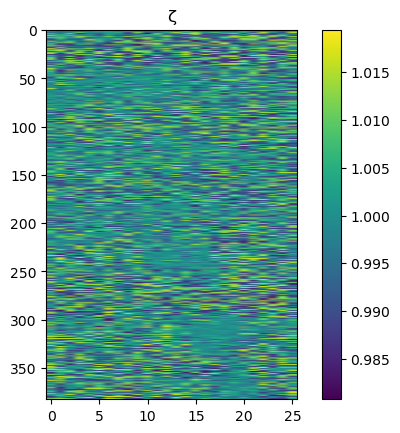

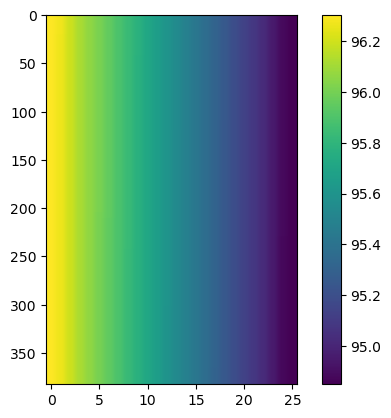

In [263]:
#plt.imshow(model.ia.detach().cpu().numpy()[0,0], aspect=aspect)
aspect = 0.1
plt.imshow(zeta.detach().cpu().numpy()[1], aspect=aspect); plt.colorbar(); plt.title('ζ'); plt.show()


#plt.imshow(np.abs(zeta.detach().cpu().numpy()[1]-1), aspect=aspect); plt.colorbar(); plt.show()
#plt.imshow(torch.abs(drec-drefs).detach().cpu().numpy()[1], aspect=aspect); plt.colorbar(); plt.show()
plt.imshow(drefs[0].detach().cpu().numpy(), aspect=aspect); plt.colorbar(); plt.show()
#plt.imshow(drefs.detach().cpu().numpy()[0], aspect=aspect); plt.colorbar(); plt.show()
#grid = torch.stack(torch.meshgrid(torch.linspace(-1,1,zeta.shape[-2]),torch.linspace(-1,1,zeta.shape[-1]),indexing='ij'), dim=-1).flip(-1)[None,]
#plt.imshow(np.log1p(np.log1p(np.abs(dataset.slc[1]))), aspect=aspect); plt.title('HV'); plt.show()

In [725]:
import Model_IceVVHHr
importlib.reload(Model_IceVVHHr)

device = 'cuda'

'''
RETRIEVE ICE REFRACTIVE INDEX PARAMETER (for thickness inversion using autofocus algorithm)
'''
grid = torch.stack(torch.meshgrid(torch.linspace(-1,1,zeta.shape[-2]),torch.linspace(-1,1,zeta.shape[-1]),indexing='ij'), dim=-1).flip(-1)[None,]

vvhhr = torch.as_tensor(np.abs(dataset.slc[3])/np.abs(dataset.slc[0])).to(torch.float32).to(device)
#vvhhr = F.grid_sample(vvhhr[None,None,], grid.to(device), mode='bicubic')[0,0]
tmp_ia = torch.as_tensor(dataset.ia).to(torch.float32).to(device)
#ia = F.grid_sample(ia[None,None,], grid.to(device))[0,0]

m_vvhhr = Model_IceVVHHr.IceVVHHr(tmp_ia.shape).to(device)
optimizer = torch.optim.Adam(m_vvhhr.parameters(), lr=0.01)

for i in range(50):
    optimizer.zero_grad()
    loss = torch.nanmean((m_vvhhr(tmp_ia) - vvhhr)**2)
    loss.backward()
    optimizer.step()

rdie = F.grid_sample(vvhhr[None,None,],grid.to(device), mode='bilinear')[0,0]
#rdie = m_vvhhr.rdie.detach()

del(tmp_ia, vvhhr, m_vvhhr)
torch.cuda.empty_cache()
#plt.imshow((rdie.detach().cpu().numpy()), aspect=0.5); plt.colorbar(); plt.title('rel. dielectric constant'); plt.show()

/tmp/ipykernel_2715/198982515.py:11: RuntimeWarning: invalid value encountered in divide
  vvhhr = torch.as_tensor(np.abs(dataset.slc[3])/np.abs(dataset.slc[0])).to(torch.float32).to(device)


In [257]:
model = Model_PhaseError.SimpleLayer(ia, rg, zeta.shape[0], device='cuda', dtype=zeta.dtype)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

for i in range(500):
    optimizer.zero_grad()
    loss = torch.nanmean((model() - zeta)**2)# + (1 - zeta.min(dim=0,keepdim=True)[0]))**2)
    #loss += 0.05*torch.nanmean((model.n_ice - rdie.detach()**0.5)**2)
    loss += 100000*torch.nanmean((model.n_ice - 1.6)**2)
    #loss += model.n_ice.std(dim=1).sum()**2
    #model.n_ice = 1.6
    
    loss.backward()
    optimizer.step()

Text(0.5, 1.0, 'n_ice (HV)')

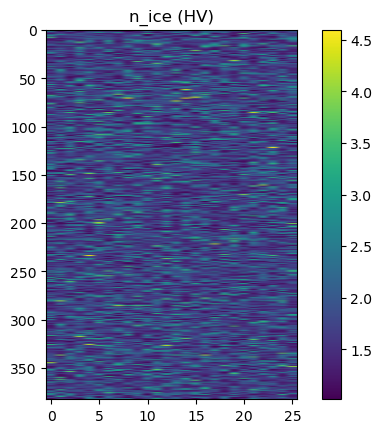

In [260]:
plt.imshow(model.n_ice[0,1].detach().cpu().numpy(), aspect=aspect); plt.colorbar(); plt.title('n_ice (HV)')

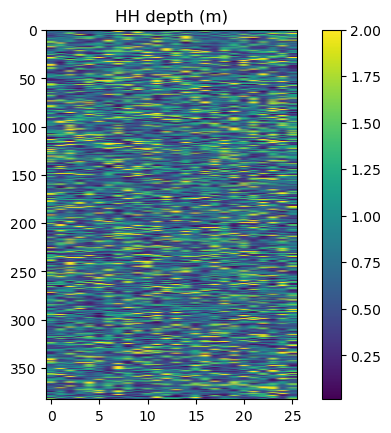

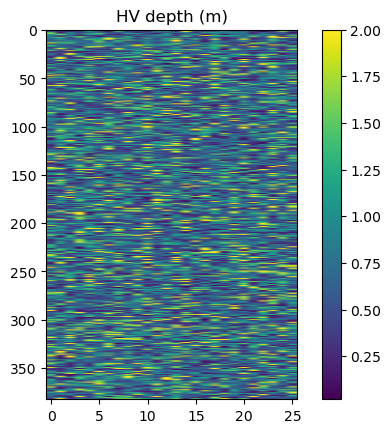

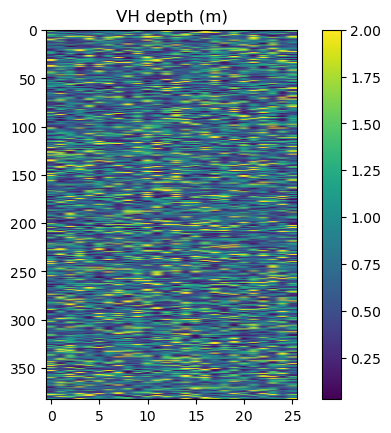

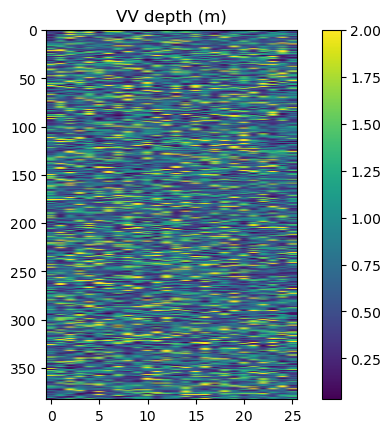

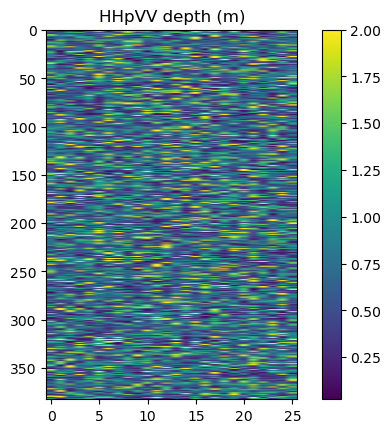

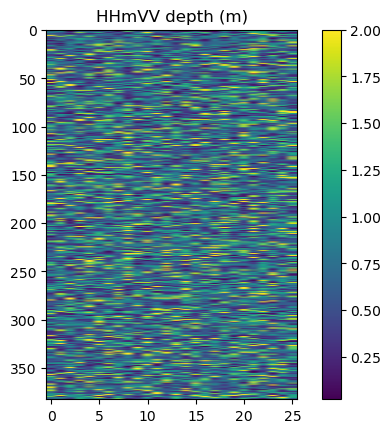

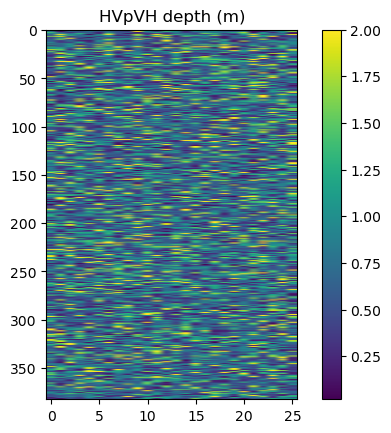

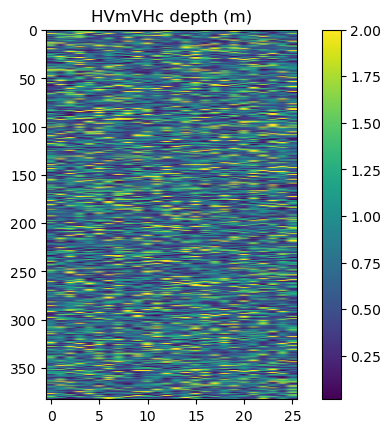

In [259]:
#aspect = 0.14
labels = ['HH','HV','VH','VV','HHpVV','HHmVV','HVpVH','HVmVHc','LL','LR','RL','RR']

#tmp = F.interpolate(model.depth, scale_factor=8, mode='bilinear', align_corners=False).flip(-2)
tmp = model.depth
#tmp = F.interpolate(tmp, scale_factor=0.5, mode='bilinear', align_corners=False)
tmp = tmp.detach().cpu().numpy()
tmp[tmp > 2] = 2
for i in range(8):
    plt.imshow(tmp[0,i], aspect=aspect); plt.colorbar(); plt.title(f'{labels[i]} depth (m)'); plt.show()


#span = 1/tmp.std(axis=1)[0]
#span = model.n_ice.detach().cpu().numpy().std(axis=1)[0]#np.log(tmp.mean(axis=1)[0])
#span = np.abs(tmp - tmp.transpose(1,0,2,3)).max(axis=0).max(axis=0)
#span = scipy.ndimage.gaussian_filter(np.log1p(np.log1p(span)), 1)
#plt.imshow(span, aspect=aspect); plt.colorbar(); plt.title('maximum depth span (m)'); plt.show()
#plt.imshow(tmp > 1, aspect=aspect); plt.title('depth span > 1 m'); plt.show()

#HH_abs = F.grid_sample(torch.as_tensor(np.abs(dataset.slc[0])).to(torch.float32)[None,None,],grid)[0,0]
#HV_abs = F.grid_sample(torch.as_tensor(np.abs(dataset.slc[1])).to(torch.float32)[None,None,],grid.cpu())[0,0]
#plt.imshow(HH_abs, aspect=0.3); plt.show()
#plt.imshow(HV_abs, aspect=aspect); plt.show()

7 24
ice ho!


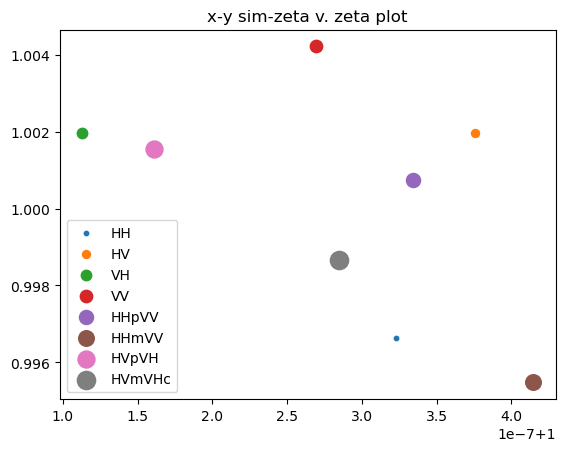

In [212]:
#plt.plot(tmp[0,:,100,35])
xi, yi = np.random.rand(2)
xi = int(xi*tmp.shape[-2])
yi = int(yi*tmp.shape[-1])
colura = np.linspace(0,255,12)
tmpx = model()[0].cpu().detach().numpy()#model.depth.detach().cpu().numpy()[0]
tmpy = zeta#model()[0]

for i in range(zeta.shape[0]):
    plt.scatter(tmpx[i,xi,yi], tmpy[i,xi,yi].cpu().detach().numpy(), s=colura[i]+10)
plt.title('x-y sim-zeta v. zeta plot')
plt.legend(labels)
print(xi,yi)
if(xi > 250 and yi < 10): print('land ho!')
if(xi < 175): print('ice ho!')

In [267]:
tmp.shape

























(1, 12, 1529, 52)